In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
raw_data = c2c.load_file('sample_data/shimadzu_C2C005.qgd')
raw_data.readTIC()
raw_data.getBPC()

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
Number of MS1 scans: 106680


In [ ]:
results_df = pd.read_excel('sample_data/c2c-005_results_final.xlsx')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI,DBE,CNum (RT),PI,N,A,Class,Cnum_Final,Class_Final
0,9.5858,9.57,2.15,26802,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812,0,8,221.60,38.48,33.92,PI,9,PI
1,9.7208,9.70,2.25,13021,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816,-1,-1,209.52,112.85,62.40,PI,9,PI
2,10.0542,10.03,2.25,82421,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825,0,8,191.22,33.01,8.88,PI,9,PI
3,11.0592,11.03,2.55,11428,7,65.0:8.58 66.2:9.76 67.15:14.01 67.2:26.67 69....,141.00,10,854,-1,-1,220.66,66.06,10.51,PI,10,PI
4,11.1900,11.17,2.40,165575,6,69.15:14.88 70.15:17.24 71.1:9.45 71.15:100.0 ...,127.20,9,858,0,9,174.18,21.51,0.00,PI,9,PI


In [4]:
colors = {
    'PI': '#e84035',
    'N': '#5fa381',
    'O': '#004c93',
    'A': '#782f88',
    'PAH': '#a68eca',
    'X': '#a9a9a9'
}

classes = dict({'PI':0, 'N':1, 'O':1, 'A':4, 'X':-1})

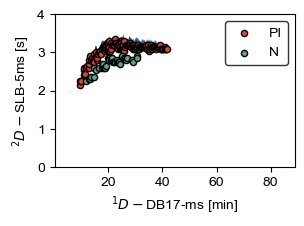

In [ ]:
cm = 1/2.54  # centimeters in inches

fig, ax = plt.subplots(figsize=(8*cm, 6*cm))

plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 10,
    "font.family": "Arial"
})

xmin = None
xmax = None
ymin = None
ymax = None

c2c.plot2d(fig, ax,
           raw_data.rt, raw_data.bpc,
           mod_time=4, shift=1, solvent_cut=0,
           color_range=(8, 80), axis_labels=('DB17-ms', 'SLB-5ms'),
           cbar=False)

for cl in classes.keys():
    sub_df = results_df[results_df['Class_Final'] == cl]

    if len(sub_df) > 0 :
        ax.scatter(sub_df['RT 1d (min)'], sub_df['RT 2d (s)'],
                   s=20,
                   label=cl,
                   edgecolors='black',
                   color=colors[cl])

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.legend()
ax.legend(frameon=True, facecolor='white', edgecolor='black')

plt.tight_layout()

plt.savefig('sample_data/SHI_C2C005_with class.png', dpi=1200)
plt.show()

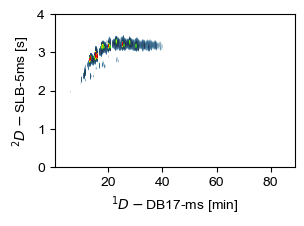

In [ ]:
cm = 1/2.54  # centimeters in inches

fig, ax = plt.subplots(figsize=(8*cm, 6*cm))

plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 10,
    "font.family": "Arial"
})

xmin = None
xmax = None
ymin = None
ymax = None

c2c.plot2d(fig, ax,
           raw_data.rt, raw_data.bpc,
           mod_time=4, shift=1, solvent_cut=0,
           color_range=(8, 80), axis_labels=('DB17-ms', 'SLB-5ms'),
           cbar=False)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.tight_layout()

plt.savefig('sample_data/SHI_C2C005_without class.png', dpi=1200)
plt.show()